In [1]:
from sklearn.datasets import load_breast_cancer
import pandas as pd

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Target classes:", data.target_names)

Features shape: (569, 30)
Target shape: (569,)
Target classes: ['malignant' 'benign']


In [5]:
import pandas as pd
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Target classes:", data.target_names)
print("\nClass distribution:")
print(pd.Series(y).value_counts())

Features shape: (569, 30)
Target shape: (569,)
Target classes: ['malignant' 'benign']

Class distribution:
1    357
0    212
Name: count, dtype: int64


In [6]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for fold, (train_index, val_index) in enumerate(skf.split(X, y), start=1):
    y_train = y.iloc[train_index] if isinstance(y, pd.Series) else y[train_index]
    y_val = y.iloc[val_index] if isinstance(y, pd.Series) else y[val_index]

    print(f"Fold {fold}")
    print("Training samples:", len(train_index))
    print("Validation samples:", len(val_index))
    print("Validation class counts:")
    print(pd.Series(y_val).value_counts().sort_index().to_dict())
    print()

Fold 1
Training samples: 455
Validation samples: 114
Validation class counts:
{0: 43, 1: 71}

Fold 2
Training samples: 455
Validation samples: 114
Validation class counts:
{0: 43, 1: 71}

Fold 3
Training samples: 455
Validation samples: 114
Validation class counts:
{0: 42, 1: 72}

Fold 4
Training samples: 455
Validation samples: 114
Validation class counts:
{0: 42, 1: 72}

Fold 5
Training samples: 456
Validation samples: 113
Validation class counts:
{0: 42, 1: 71}



In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

scores = cross_val_score(
    model,
    X,
    y,
    cv=skf,
    scoring="accuracy"
)

print("Fold scores:", scores.round(3))
print("Mean accuracy:", round(scores.mean(), 3))
print("Standard deviation:", round(scores.std(), 3))

Fold scores: [0.974 0.947 0.965 0.991 0.991]
Mean accuracy: 0.974
Standard deviation: 0.017


[[41  1]
 [ 1 71]]


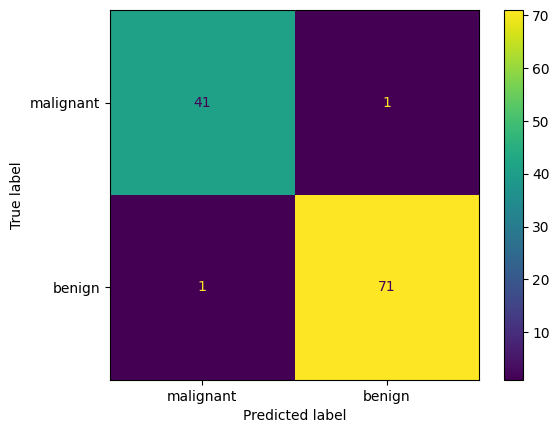

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
).plot()

plt.show()

In [9]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Treat malignant (class 0) as the positive class
y_test_malignant = (y_test == 0).astype(int)
y_pred_malignant = (y_pred == 0).astype(int)

precision = precision_score(
    y_test_malignant,
    y_pred_malignant
)

recall = recall_score(
    y_test_malignant,
    y_pred_malignant
)

f1 = f1_score(
    y_test_malignant,
    y_pred_malignant
)

print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-score:  {f1:.3f}")

print("\nFull classification report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))

Precision: 0.976
Recall:    0.976
F1-score:  0.976

Full classification report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



ROC-AUC: 0.995


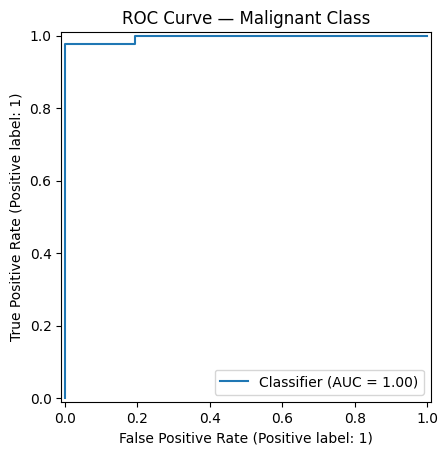

In [10]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay
import matplotlib.pyplot as plt

# Probability of malignant (class 0)
y_prob_malignant = model.predict_proba(X_test)[:, 0]

auc = roc_auc_score(
    (y_test == 0).astype(int),
    y_prob_malignant
)

print(f"ROC-AUC: {auc:.3f}")

RocCurveDisplay.from_predictions(
    (y_test == 0).astype(int),
    y_prob_malignant
)

plt.title("ROC Curve — Malignant Class")
plt.show()

In [11]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

param_grid = {
    "logisticregression__C": [0.01, 0.1, 1, 10, 100]
}

grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=skf,
    scoring="accuracy"
)

grid.fit(X_train, y_train)

print("Best C:", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 3))

Best C: {'logisticregression__C': 0.1}
Best CV accuracy: 0.982


In [12]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

best_model = grid.best_estimator_

y_pred_tuned = best_model.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, y_pred_tuned), 3))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

print("\nClassification report:")
print(classification_report(y_test, y_pred_tuned, target_names=data.target_names))

Test accuracy: 0.974

Confusion matrix:
[[40  2]
 [ 1 71]]

Classification report:
              precision    recall  f1-score   support

   malignant       0.98      0.95      0.96        42
      benign       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114

